# 04b - Modeling: Grid Search Hyperparameter

## Tujuan
Menentukan konfigurasi terbaik untuk jumlah topik K dan prior Dirichlet
(alpha, eta) melalui grid search exhaustive.

## Asal (Input)
`data/intermediate/dataset_preprocessed.csv` + `dictionary.gensim`

## Keluaran (Output)
`model/hyperparameter_results.csv` - hasil 84 konfigurasi

## Ruang Grid
| Parameter | Nilai yang diuji |
|:---|:---|
| K | 4, 5, 6, 7, 8, 9, 10 (7 nilai) |
| Alpha | symmetric, asymmetric, 0.01, 0.1 (4 nilai) |
| Eta | symmetric, 0.01, 0.1 (3 nilai) |

**Total: 7 x 4 x 3 = 84 konfigurasi**, masing-masing dengan passes=10.

## Catatan Penting tentang Pemilihan K
Grid search ini menunjukkan **K=9 mencapai C_V tertinggi (0,4314)**, bukan K=8.
K=8 dipilih atas pertimbangan gabungan: jumlah dokumen per topik lebih memadai
(minimum 21) dan struktur topik lebih mudah diinterpretasikan. Hal ini
dijelaskan secara transparan pada Bab IV skripsi.

In [1]:
import sys, io as _io
from pathlib import Path
_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(_ROOT))
try:
    sys.stdout.reconfigure(encoding='utf-8', errors='replace')
except Exception:
    pass

import pandas as pd, numpy as np
from src import config as C
C.ensure_dirs()
print(C.describe())

KONFIGURASI PROYEK
  Repo          : C:\Users\HAJIWAHYU\Downloads\lda-topik-skripsi-si-uinrf-main
  Dokumen akhir : 285 (2021, 2022, 2023, 2024, 2025)
  Vocabulary    : 1849
  Model LDA     : K=8, alpha=asymmetric, eta=auto, passes=30, iterations=500, seed=42
  Inferensi     : Online Variational Bayes (bukan Gibbs Sampling)
  C_V resmi     : 0.4256
  Cutoff data   : 19 September 2026

## Langkah 1 - Jalankan Grid Search

In [2]:
# Grid search penuh = 84 konfigurasi (K=4..10 x 4 alpha x 3 eta), ~20-40 menit.
# Set True untuk menjalankan ulang. PERINGATAN: menjalankan ulang akan
# MENIMPA model/hyperparameter_results.csv, dan angka pada Tabel 6 skripsi
# diturunkan dari berkas itu. Default False agar angka skripsi tetap terpakai.
RUN_GRID = False

if RUN_GRID:
    from src import grid_search
    grid_search.main()
else:
    print("RUN_GRID=False -> memakai artefak yang sudah tersimpan:")
    print("  ", C.HYPERPARAMS_CSV)
    print("  Jumlah konfigurasi:", len(pd.read_csv(C.HYPERPARAMS_CSV)))
    print("  Untuk menjalankan ulang: python -m src.grid_search")

RUN_GRID=False -> memakai artefak yang sudah tersimpan:
   C:\Users\HAJIWAHYU\Downloads\lda-topik-skripsi-si-uinrf-main\model\hyperparameter_results.csv
  Jumlah konfigurasi: 84
  Untuk menjalankan ulang: python -m src.grid_search

## Langkah 2 - Analisis Hasil: C_V Tertinggi per K

In [3]:
hp = pd.read_csv(C.HYPERPARAMS_CSV)
print(f'Total konfigurasi: {len(hp)}')
print()
print('=== C_V MAKSIMUM PER K ===')
for k, grp in hp.groupby('k'):
    print(f'  K={k:2d}  C_V max = {grp["coherence_cv"].max():.4f}   '
          f'C_V mean = {grp["coherence_cv"].mean():.4f}')

Total konfigurasi: 84

=== C_V MAKSIMUM PER K ===
  K= 4  C_V max = 0.3605   C_V mean = 0.3328
  K= 5  C_V max = 0.3756   C_V mean = 0.3619
  K= 6  C_V max = 0.3909   C_V mean = 0.3657
  K= 7  C_V max = 0.4142   C_V mean = 0.3898
  K= 8  C_V max = 0.3871   C_V mean = 0.3776
  K= 9  C_V max = 0.4314   C_V mean = 0.4058
  K=10  C_V max = 0.3993   C_V mean = 0.3858

## Langkah 3 - 10 Konfigurasi Teratas

In [4]:
top = hp.sort_values('coherence_cv', ascending=False).head(10)
print(top[['k','alpha','eta','coherence_cv','coherence_umass']].to_string(index=False))

 k      alpha       eta  coherence_cv  coherence_umass
 9 asymmetric      0.01      0.431440       -10.558549
 9 asymmetric symmetric      0.420441       -10.272741
 9 asymmetric       0.1      0.419460       -10.444771
 7       0.01      0.01      0.414190       -10.355549
 7       0.01       0.1      0.411630       -10.260681
 7       0.01 symmetric      0.407383       -10.184536
 9        0.1       0.1      0.404600       -10.837460
 9        0.1 symmetric      0.404600       -10.839440
 9  symmetric symmetric      0.403029       -10.842697
 9  symmetric       0.1      0.403029       -10.842113

## Langkah 4 - Elbow Curve

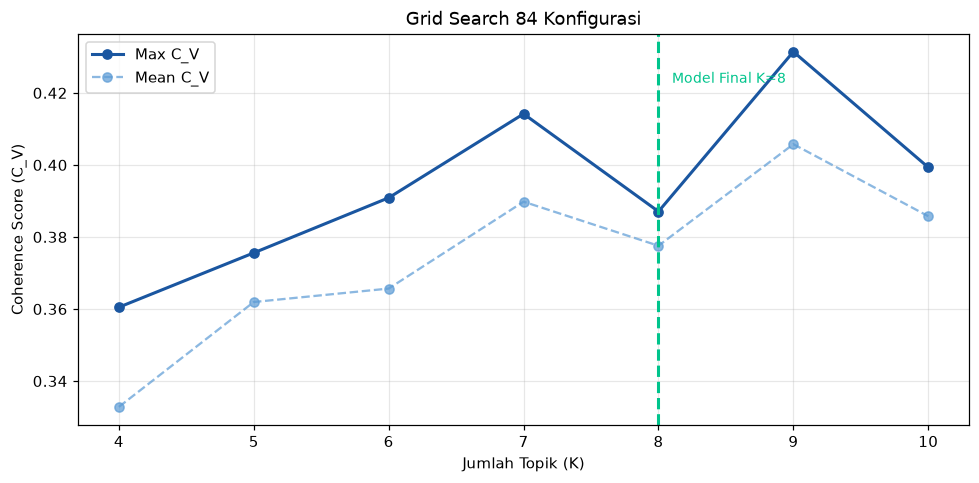

In [5]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

sweep = hp.groupby('k')['coherence_cv'].agg(['max','mean']).reset_index()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(sweep['k'], sweep['max'], '-o', color='#1A56A0', linewidth=2, label='Max C_V')
ax.plot(sweep['k'], sweep['mean'], '--o', color='#5B9BD5', alpha=0.7, label='Mean C_V')
ax.axvline(8, color='#00C48C', linestyle='--', linewidth=2)
ax.text(8.1, sweep['max'].max()*0.98, 'Model Final K=8', color='#00C48C', fontsize=9)
ax.set_xlabel('Jumlah Topik (K)'); ax.set_ylabel('Coherence Score (C_V)')
ax.set_title('Grid Search 84 Konfigurasi')
ax.set_xticks(sorted(hp['k'].unique())); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

## Ringkasan Fase 04b - Grid Search

| K | C_V maksimum | Catatan |
|---:|---:|:---|
| 4 | 0,3605 | |
| 5 | 0,3756 | |
| 6 | 0,3909 | |
| 7 | 0,4142 | |
| 8 | 0,3871 | **Dipilih** - struktur lebih seimbang |
| 9 | **0,4314** | C_V tertinggi, tapi topik terlalu ringkas |
| 10 | 0,3993 | |

Pemilihan K=8 adalah keputusaninterpretif combined: bukan semata C_V
tertinggi, melainkan menimbang koherensi, jumlah dokumen per topik,
dan interpretabilitas.

## Peta Artefak

| Artefak | Dibuat oleh | Consumed by |
|:---|:---|:---|
| `model/hyperparameter_results.csv` | Notebook 04b | Notebook 04 (-informed) |